In [1]:
%load_ext autoreload
%autoreload 2

import glob

import cv2
import matplotlib.pyplot as plt
import numpy as np

from tflite_inference import TFLiteInferer

2024-10-11 14:13:14.790607: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-11 14:13:14.809426: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-11 14:13:14.814898: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-11 14:13:14.830023: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-11 14:13:15.724677: W tensorflow/compiler/tf2

TensorFlow version:  2.17.0


In [21]:
# tst_img_path = "../../rtos_sensor/projects/alif_ml-embedded-evaluation-kit_pg/resources/pg_object_detection/samples/img_320.bmp"
tst_img_path = sorted(glob.glob("/home/klymy/data/people_detection/filtered_v3_margin_15/images/algotest/*.jpg"))[1040]

img = cv2.cvtColor(cv2.imread(tst_img_path), cv2.COLOR_BGR2RGB)

ORIGINAL_H, ORIGIAL_W, _ = img.shape
W = H = 320
RATIO = W / ORIGIAL_W

In [22]:
def draw(img, detections):
    tmp = img.copy()
    for box in detections:
        cv2.rectangle(tmp, (box[:2] / RATIO).astype(int), ((box[:2].astype(int) + box[2:4]) / RATIO).astype(int) , (255, 0, 0), 1)

    for p in detections:
        cv2.circle(tmp, (p[-2:] // RATIO).astype(int), 2, (255, 0, 0), 3)

    plt.figure(figsize=(8, 8))
    plt.imshow(tmp)

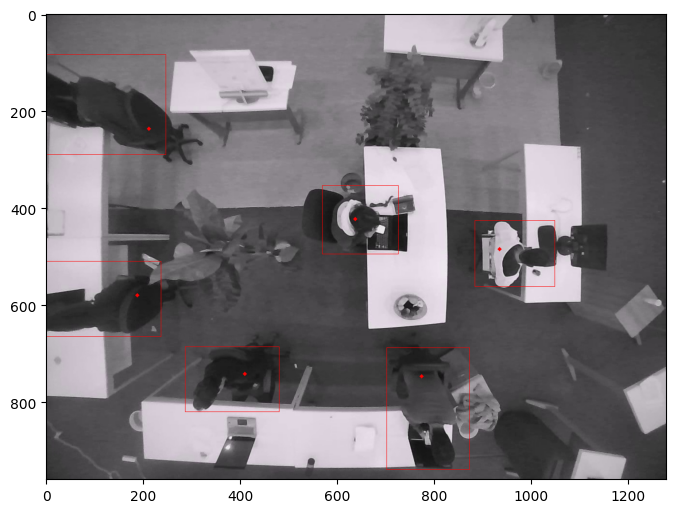

In [23]:

inferer = TFLiteInferer(
    yolo_pth="results/filtered_v3_margin_15/weights/best_saved_model/best_full_integer_quant.tflite",
    head_pth="results/filtered_v3_margin_15/weights/head_saved_model/head_float32.tflite",
)

detections = inferer.infer(img)

draw(img ,detections)